# Actividad 2. Del mundo real al clustering: perfiles de riesgo cardiometabólico en NHANES

**Técnicas de Análisis No Supervisado** · Especialización en Análisis Estadístico para Ciencia de Datos · Universidad de La Salle

## 1. Configuración

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu

from sklearn.preprocessing import PowerTransformer
from sklearn.decomposition import PCA

from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_samples,
    silhouette_score,
)

from nhanes_no_supervisado.config import ARCHIVO_DEPURADO, SEMILLA, ruta_figuras
from nhanes_no_supervisado.datos import cargar_crudos

RUTA_FIGURAS = ruta_figuras(2)

## 2. Problema, base de datos y objetivo

La Encuesta Nacional de Examen de Salud y Nutrición (NHANES, por sus siglas en inglés) es un programa del Centro Nacional de Estadísticas de Salud (NCHS) de los Centros para el Control y la Prevención de Enfermedades (CDC) de Estados Unidos, diseñado para evaluar el estado de salud y nutrición de adultos y niños del país (National Center for Health Statistics [NCHS], s.f.-a). A diferencia de otras encuestas de salud, NHANES combina entrevistas en el hogar con exámenes físicos y pruebas de laboratorio realizados en centros móviles, de modo que cada participante cuenta tanto con información autorreportada (características sociodemográficas, hábitos y antecedentes médicos) como con mediciones objetivas (antropometría, presión arterial y biomarcadores en sangre) (NCHS, s.f.-a).

Además, la encuesta emplea un muestreo probabilístico complejo y multietápico y se publica en ciclos de dos años, cada uno dividido en módulos que se vinculan mediante un identificador único por participante (`SEQN`) (NCHS, s.f.-a). En este trabajo se emplea el ciclo 2017–2018, el último completo antes de la pandemia, del cual se seleccionaron ocho módulos con variables antropométricas, de presión arterial, glucémicas y lipídicas.

La circunferencia de cintura, la presión arterial, la glucosa en ayunas, los triglicéridos y el colesterol HDL son los cinco componentes del síndrome metabólico, un conjunto de alteraciones que aumenta el riesgo de enfermedad cardiovascular y de diabetes tipo 2 (Alberti et al., 2009). A ellos se suma la hemoglobina glicada (HbA1c), que complementa la evaluación del estado glucémico (American Diabetes Association Professional Practice Committee [ADA], 2025). Por ello, la pregunta guía de esta actividad es: *¿Cómo podemos utilizar clustering para identificar perfiles de riesgo cardiometabólico en adultos?*

## 3. Población de estudio

### 3.1 Carga y unión de los módulos

In [2]:
df = cargar_crudos()
print(f"La base unida tiene {df.shape[0]:,} participantes y {df.shape[1]} variables.")
df.info()

La base unida tiene 9,254 participantes y 11 variables.
<class 'pandas.DataFrame'>
RangeIndex: 9254 entries, 93703 to 102956
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   edad                9254 non-null   float64
 1   sexo                9254 non-null   float64
 2   embarazo            1110 non-null   float64
 3   cintura_cm          7601 non-null   float64
 4   imc                 8005 non-null   float64
 5   hba1c_pct           6045 non-null   float64
 6   glucosa_mgdl        2891 non-null   float64
 7   trigliceridos_mgdl  2834 non-null   float64
 8   hdl_mgdl            6738 non-null   float64
 9   diabetes_dx         8897 non-null   float64
 10  sistolica_mmhg      6717 non-null   float64
dtypes: float64(11)
memory usage: 795.4 KB


### 3.2 Selección de adultos no embarazadas

In [3]:
# Adultos de 20 años o más, excluyendo embarazadas (RIDEXPRG = 1).
# En los hombres RIDEXPRG es NaN; la condición == 1 no los excluye.
es_adulto = df["edad"] >= 20
es_embarazada = df["embarazo"] == 1

df_adultos = df[es_adulto & ~es_embarazada].drop(columns="embarazo").copy()

print(f"Adultos: {es_adulto.sum():,}")
print(f"Embarazadas excluidas: {(es_adulto & es_embarazada).sum()}")
print(f"Población de estudio: {len(df_adultos):,}")

Adultos: 5,569
Embarazadas excluidas: 55
Población de estudio: 5,514


La población de estudio se restringe a adultos de 20 años o más, que es el corte habitual en los estudios sobre síndrome metabólico basados en NHANES (Hirode & Wong, 2020). Asimismo, se excluyen las participantes con embarazo confirmado (`RIDEXPRG = 1`), puesto que la gestación eleva de forma marcada los lípidos circulantes, en especial los triglicéridos (Wang et al., 2016), de modo que sus valores no representarían el perfil metabólico habitual. Por el contrario, se conservan las mujeres en quienes no fue posible determinar el embarazo (`RIDEXPRG = 3`), ya que excluirlas supondría asumir una condición que no consta en los datos; además, NHANES solo publica esta variable para mujeres de 20 a 44 años, por lo que en el resto de participantes aparece como faltante (NCHS, 2020a).

## 4. Clasificación de variables

| Variable | Código NHANES | Tipo | Subtipo | Unidad | Rol | Descripción |
|---|---|---|---|---|---|---|
| `edad` | RIDAGEYR | Cuantitativa | Discreta | años | Filtro y perfilamiento | Edad en años cumplidos; NHANES registra como 80 a todos los mayores de 80 años |
| `sexo` | RIAGENDR | Cualitativa | Nominal dicotómica | 1 = hombre, 2 = mujer | Perfilamiento | No entra al modelo; sirve para describir los grupos |
| `cintura_cm` | BMXWAIST | Cuantitativa | Continua de razón | cm | Clustering | Indicador de obesidad abdominal, componente del síndrome metabólico |
| `imc` | BMXBMI | Cuantitativa | Continua de razón | kg/m² | Candidata | Probablemente redundante con la cintura; se decide en el EDA |
| `sistolica_mmhg` | BPXSY1–BPXSY4 | Cuantitativa | Continua de razón | mmHg | Clustering | Promedio de las lecturas disponibles (hasta cuatro) |
| `hba1c_pct` | LBXGH | Cuantitativa | Continua de razón | % | Clustering | Refleja la glucemia promedio de los últimos dos a tres meses; no requiere ayuno |
| `glucosa_mgdl` | LBXGLU | Cuantitativa | Continua de razón | mg/dL | Clustering | Glucosa en ayunas; solo se mide en los participantes de la sesión matutina |
| `trigliceridos_mgdl` | LBXTR | Cuantitativa | Continua de razón | mg/dL | Clustering | Se mide en ayunas, en la misma submuestra que la glucosa |
| `hdl_mgdl` | LBDHDD | Cuantitativa | Continua de razón | mg/dL | Clustering | Único componente protector: valores más altos indican menor riesgo |
| `diabetes_dx` | DIQ010 | Cualitativa | Nominal | 1 = sí, 2 = no, 3 = limítrofe, 7 = se negó, 9 = no sabe | Validación externa | Diagnóstico médico autorreportado; nunca entra al modelo |

Las descripciones de la tabla se basan en la documentación del ciclo 2017–2018 (NCHS, 2020a, 2020b), en los criterios del síndrome metabólico (Alberti et al., 2009) y en los criterios diagnósticos de diabetes (ADA, 2025). En consecuencia, el clustering se construye solo con variables cuantitativas continuas, mientras que el sexo y la edad se reservan para describir los grupos y el diagnóstico de diabetes para la validación externa. Además, tres características de la tabla condicionan las decisiones posteriores: el tope de 80 años en la edad, el sentido inverso de la HDL respecto al riesgo y el requisito de ayuno de la glucosa y los triglicéridos, que reduce el número de participantes con datos completos.

## 5. Análisis exploratorio de datos (EDA)

In [4]:
# Variables cuantitativas continuas candidatas al clustering
VARIABLES_CONTINUAS = [
    "cintura_cm", "imc", "sistolica_mmhg", "hba1c_pct",
    "glucosa_mgdl", "trigliceridos_mgdl", "hdl_mgdl",
]
continuas = df_adultos[VARIABLES_CONTINUAS]

Para el análisis numérico solo se consideran las variables cuantitativas continuas. El sexo y el diagnóstico de diabetes son variables nominales almacenadas como códigos (1, 2, 3, 7, 9), de modo que su media, su asimetría o sus "atípicos" carecen de significado: un 9 en `diabetes_dx` no es un valor extremo, sino la respuesta "no sabe". Además, ninguna de las dos entra al modelo, pues el sexo se reserva para describir los grupos y el diagnóstico de diabetes para la validación externa.

### 5.1 Faltantes

In [5]:
nulos = df_adultos.isna().sum().to_frame("n_nulos")
nulos["porcentaje"] = (nulos["n_nulos"] / len(df_adultos) * 100).round(1)
display(nulos.sort_values("n_nulos", ascending=False))

,n_nulos,porcentaje
trigliceridos_mgdl,3141,57.0
glucosa_mgdl,3099,56.2
hdl_mgdl,624,11.3
cintura_cm,621,11.3
sistolica_mmhg,566,10.3
hba1c_pct,543,9.8
imc,394,7.1
edad,0,0.0
sexo,0,0.0
diabetes_dx,0,0.0


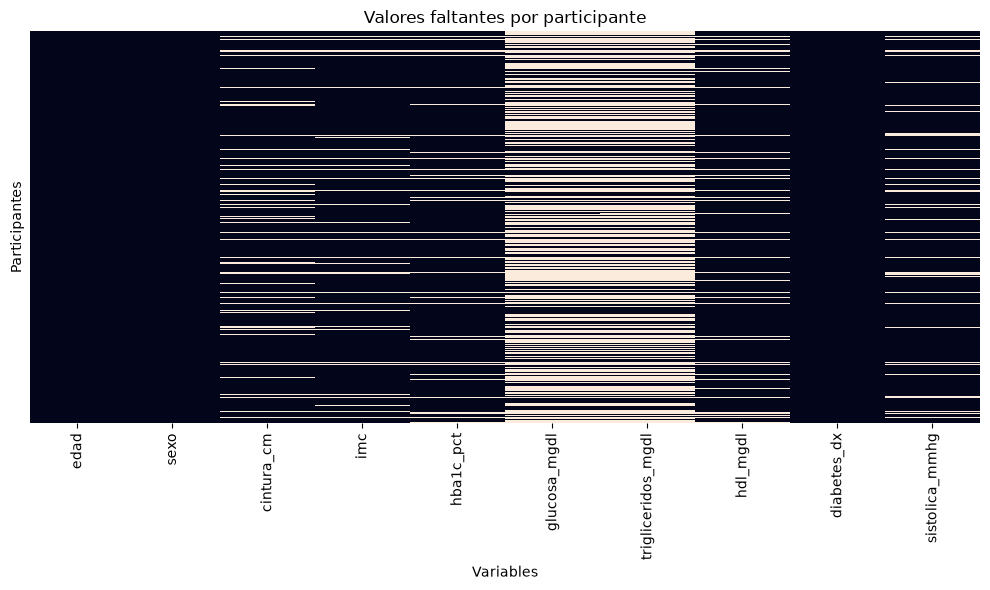

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(df_adultos.isna(), cbar=False, yticklabels=False, ax=ax)
ax.set(title="Valores faltantes por participante", xlabel="Variables", ylabel="Participantes")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "01_faltantes.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
completos_a = continuas.drop(columns="imc").dropna()
completos_b = continuas[["cintura_cm", "sistolica_mmhg", "hba1c_pct", "hdl_mgdl"]].dropna()
print(f"Opción A (6 variables): {len(completos_a):,} participantes")
print(f"Opción B (4 variables): {len(completos_b):,} participantes")

Opción A (6 variables): 2,173 participantes
Opción B (4 variables): 4,477 participantes


Las variables con mayor proporción de faltantes son la glucosa y los triglicéridos, con más de la mitad de los adultos sin medición, mientras que el resto de variables no supera el 12 %. Además, el mapa de faltantes muestra que ambas mediciones faltan en los mismos participantes, lo que concuerda con el diseño de NHANES: los participantes se asignan al azar a la sesión de la mañana o de la tarde, y solo a quienes asisten en la mañana se les solicita ayuno para medir la glucosa y los triglicéridos (NCHS, 2020b, s.f.-b). Por lo tanto, estos faltantes no indican un perfil metabólico particular, sino una medición que no se realizó.

En consecuencia, el análisis puede seguir dos caminos: conservar las seis variables con los participantes de la submuestra en ayunas (opción A, 2.173 casos completos) o prescindir de la glucosa y los triglicéridos para duplicar la muestra (opción B, 4.477 casos completos). La sección 5.2 evalúa si la primera opción introduce algún sesgo.

### 5.2 Submuestra en ayunas

In [8]:
# Comparación entre participantes dentro y fuera de la submuestra en ayunas
en_ayunas = df_adultos["glucosa_mgdl"].notna()
comparables = ["edad", "cintura_cm", "imc", "sistolica_mmhg", "hba1c_pct", "hdl_mgdl"]

filas = []
for var in comparables:
    dentro = df_adultos.loc[en_ayunas, var].dropna()
    fuera = df_adultos.loc[~en_ayunas, var].dropna()
    filas.append({
        "variable": var,
        "mediana_ayunas": dentro.median(),
        "mediana_resto": fuera.median(),
        "p_valor": mannwhitneyu(dentro, fuera).pvalue,
    })

print(f"Participantes en la submuestra en ayunas: {en_ayunas.sum():,}")
display(pd.DataFrame(filas).set_index("variable").round(3))

Participantes en la submuestra en ayunas: 2,415


,mediana_ayunas,mediana_resto,p_valor
variable,,,
edad,53.000,53.000,0.616
cintura_cm,98.900,99.700,0.235
imc,28.400,28.800,0.343
sistolica_mmhg,123.333,124.667,0.040
hba1c_pct,5.600,5.600,0.493
hdl_mgdl,51.000,50.000,0.047


La submuestra en ayunas cuenta con 2.415 participantes, y sus medianas de edad, cintura, IMC, HbA1c, presión sistólica y HDL son prácticamente iguales a las de quienes no pertenecen a ella. Si bien la presión sistólica y la HDL alcanzan diferencias estadísticamente significativas (p ≈ 0,04), estas obedecen al tamaño de la muestra y no tienen relevancia clínica, dado que equivalen a 1,3 mmHg y 1 mg/dL. Por lo tanto, trabajar con la submuestra en ayunas no introduce sesgo de selección, lo cual concuerda con su asignación aleatoria (NCHS, s.f.-b).

### 5.3 Descriptivos y distribuciones

In [9]:
def describir_extendido(data):
    """Agrega asimetría y coeficiente de variación al describe() de pandas."""
    descripcion = data.describe()
    extra = pd.DataFrame(
        [data.skew(), data.std() / data.mean()],
        index=["asimetria", "cv"],
    )
    return pd.concat([descripcion, extra])


descripcion = describir_extendido(continuas).T.sort_values("asimetria", ascending=False)
display(descripcion.round(2))

,count,mean,std,min,25%,50%,75%,max,asimetria,cv
trigliceridos_mgdl,2373.0,113.91,104.11,10.00,62.00,94.0,136.0,2684.0,9.92,0.91
glucosa_mgdl,2415.0,114.57,37.94,47.00,96.00,104.0,116.0,451.0,3.72,0.33
hba1c_pct,4971.0,5.87,1.10,3.80,5.30,5.6,6.0,16.2,3.14,0.19
hdl_mgdl,4890.0,53.18,15.68,10.00,42.00,51.0,61.0,189.0,1.33,0.29
imc,5120.0,29.83,7.40,14.20,24.80,28.6,33.5,86.2,1.28,0.25
sistolica_mmhg,4948.0,127.32,20.16,72.67,113.33,124.0,138.0,238.0,1.01,0.16
cintura_cm,4893.0,100.73,17.01,57.90,88.80,99.3,111.1,169.5,0.50,0.17


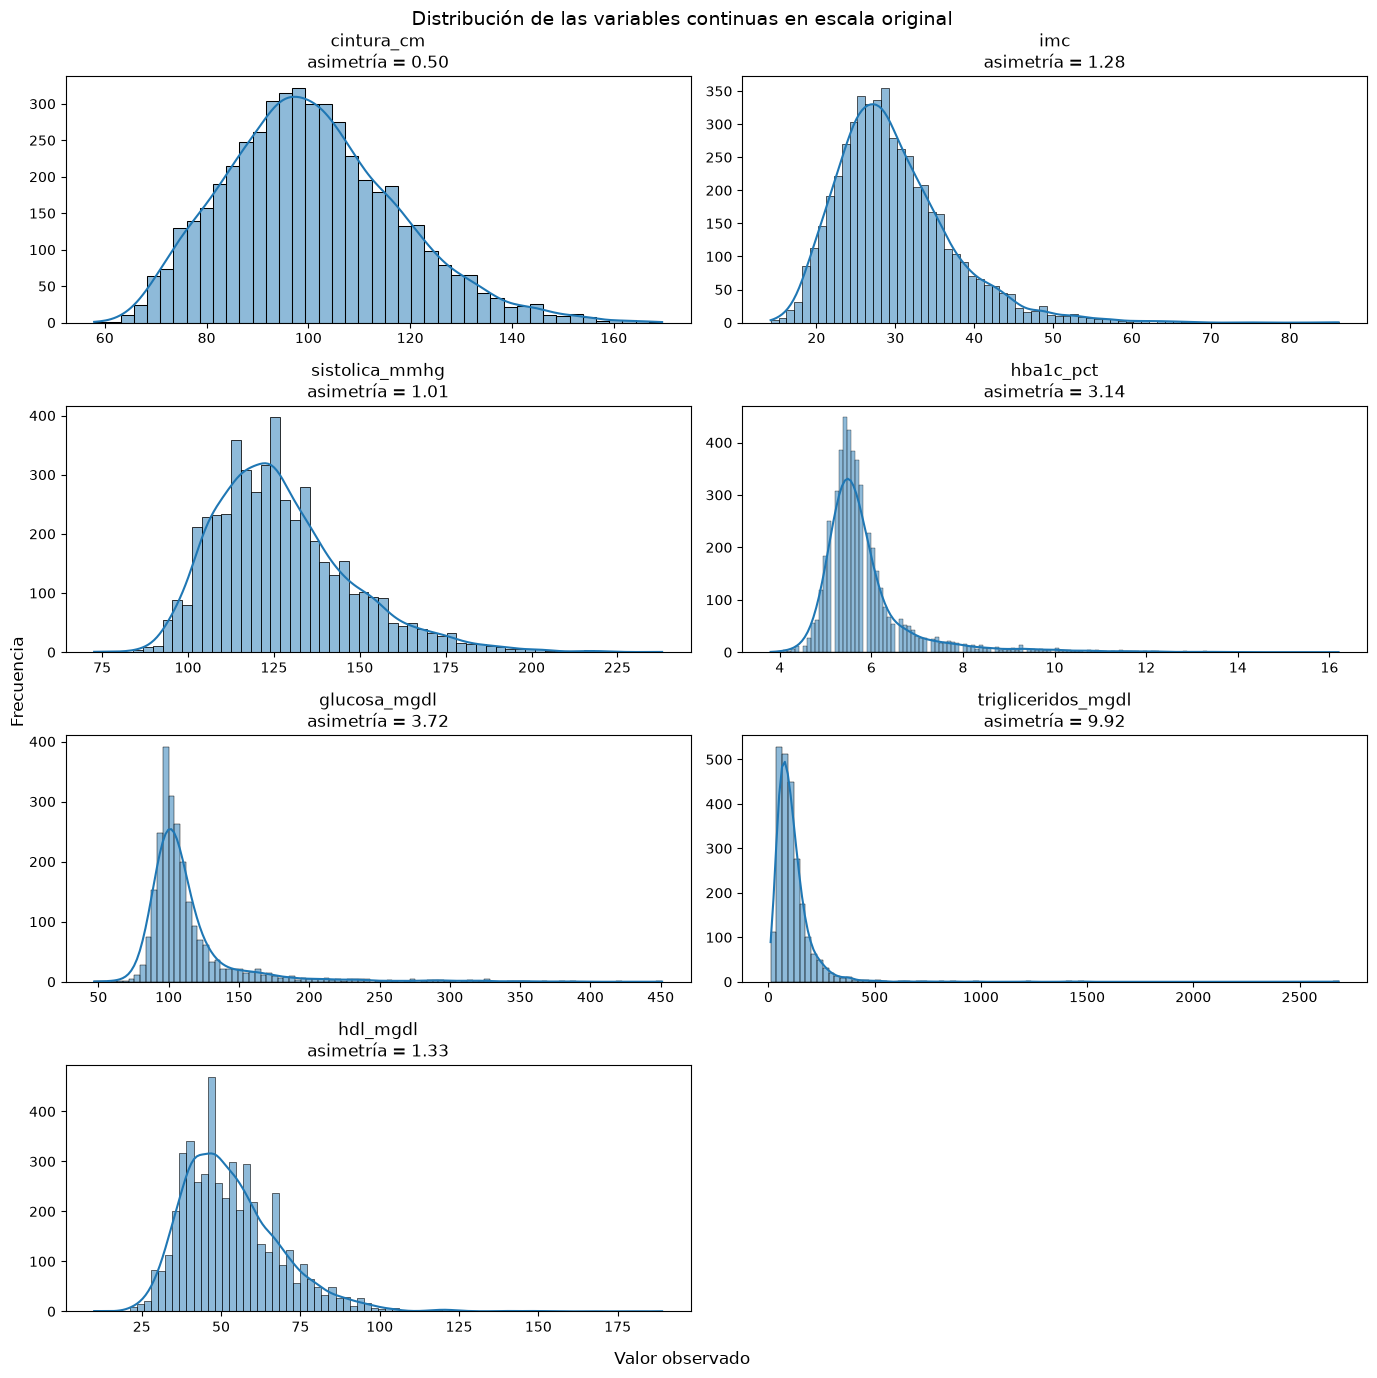

In [10]:
fig, axs = plt.subplots(4, 2, figsize=(14, 14))

for ax, columna in zip(axs.ravel(), VARIABLES_CONTINUAS):
    valores = continuas[columna]
    sns.histplot(valores, kde=True, ax=ax)
    ax.set(title=f"{columna}\nasimetría = {valores.skew():.2f}", xlabel="", ylabel="")

axs.ravel()[-1].set_visible(False)

fig.suptitle("Distribución de las variables continuas en escala original", fontsize=14)
fig.supxlabel("Valor observado")
fig.supylabel("Frecuencia")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "02_histogramas.png", dpi=150, bbox_inches="tight")
plt.show()

Todas las variables continuas presentan asimetría positiva, es decir, una cola larga hacia valores altos. Los triglicéridos son la variable más asimétrica (9,92) y la de mayor coeficiente de variación (0,91), seguidos de la glucosa (3,72) y la HbA1c (3,14), mientras que la cintura es la más cercana a la simetría (0,50). Estas colas corresponden a participantes con valores en rangos patológicos, por lo que, más que un problema de los datos, reflejan la heterogeneidad metabólica que se busca segmentar. No obstante, el modelo de mezclas gaussianas asume normalidad dentro de cada componente, de modo que será necesario aplicar una transformación que reduzca la asimetría antes del modelado.

### 5.4 Valores atípicos

In [11]:
# Regla de Tukey; el porcentaje se calcula sobre los valores observados de cada variable
q1, q3 = continuas.quantile(0.25), continuas.quantile(0.75)
ric = q3 - q1
atipicos = (continuas < q1 - 1.5 * ric) | (continuas > q3 + 1.5 * ric)

resumen_atipicos = atipicos.sum().rename("n_atipicos").to_frame()
resumen_atipicos["n_observados"] = continuas.notna().sum()
resumen_atipicos["porcentaje"] = (
    resumen_atipicos["n_atipicos"] / resumen_atipicos["n_observados"] * 100
).round(1)
display(resumen_atipicos.sort_values("porcentaje", ascending=False))

,n_atipicos,n_observados,porcentaje
glucosa_mgdl,254,2415,10.5
hba1c_pct,464,4971,9.3
trigliceridos_mgdl,120,2373,5.1
imc,152,5120,3.0
sistolica_mmhg,135,4948,2.7
hdl_mgdl,122,4890,2.5
cintura_cm,64,4893,1.3


La glucosa (10,5 %) y la HbA1c (9,3 %) concentran la mayor proporción de valores atípicos, y casi todos se ubican por encima del límite superior. Además, ese límite (146 mg/dL para la glucosa y 7,1 % para la HbA1c) supera los umbrales diagnósticos de diabetes, de 126 mg/dL en ayunas y 6,5 % respectivamente (ADA, 2025), por lo que estos atípicos corresponden a personas en rango diabético. De forma similar, el límite superior de los triglicéridos (247 mg/dL) supera el umbral de hipertrigliceridemia de 150 mg/dL (Alberti et al., 2009). Por el contrario, los atípicos de la HDL son valores altos (> 89,5 mg/dL), que en este caso indican un perfil favorable. Por lo tanto, los atípicos se conservan, ya que representan perfiles clínicos reales y no errores de medición.

### 5.5 Correlaciones

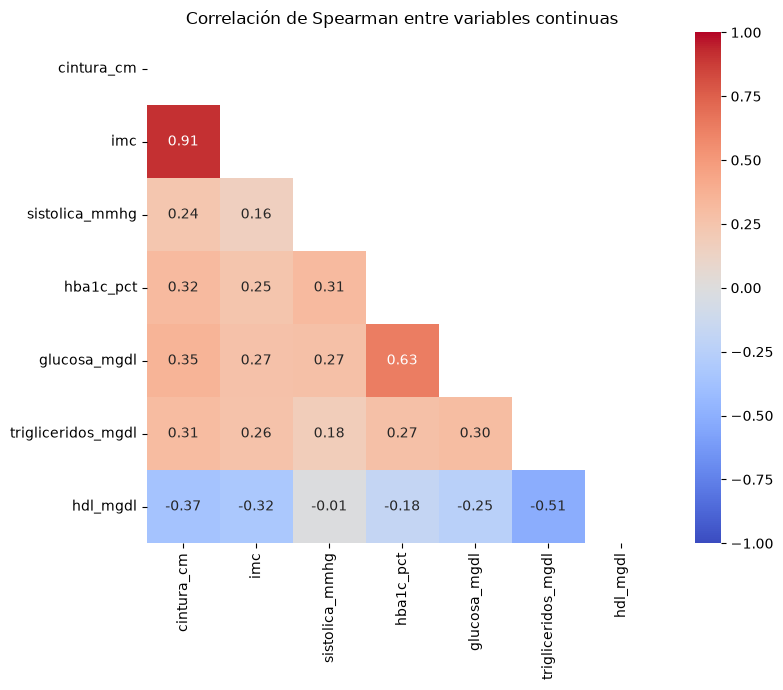

In [12]:
matriz_correlacion = continuas.corr(method="spearman")
mascara = np.triu(np.ones_like(matriz_correlacion, dtype=bool))

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    matriz_correlacion, mask=mascara, cmap="coolwarm", vmin=-1, vmax=1,
    annot=True, fmt=".2f", square=True, ax=ax,
)
ax.set_title("Correlación de Spearman entre variables continuas")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "03_correlaciones.png", dpi=150, bbox_inches="tight")
plt.show()

Dado que las variables presentan asimetría marcada y valores extremos, se emplea la correlación de Spearman, que se calcula sobre los rangos de los datos en lugar de sobre sus valores originales. De esta manera, no se deja arrastrar por los valores extremos y capta cualquier relación monótona, no solo las lineales (Schober et al., 2018).

La correlación más alta se presenta entre la cintura y el IMC (0,91), lo que indica que ambas miden prácticamente lo mismo: la adiposidad. Le sigue la relación entre la glucosa y la HbA1c (0,63), que es moderada, pues ambas miden la glucemia en ventanas de tiempo distintas. Por su parte, la HDL se correlaciona de forma negativa con las demás variables, en particular con los triglicéridos, lo que concuerda con su papel protector dentro del síndrome metabólico (Alberti et al., 2009).

### 5.6 Decisiones derivadas del EDA

En primer lugar, la cintura y el IMC presentan una correlación de Spearman de 0,91, por lo que conservar ambas duplicaría el peso de la adiposidad en el modelo. Por ello, se conserva la cintura, ya que es el componente del síndrome metabólico que mide específicamente la obesidad abdominal (Alberti et al., 2009), y se descarta el IMC. En cambio, la glucosa y la HbA1c, con una correlación de 0,63, se mantienen ambas, puesto que la primera refleja la glucemia en el momento de la toma y la segunda su promedio en los últimos dos a tres meses (ADA, 2025).

En segundo lugar, la glucosa y los triglicéridos presentan más de la mitad de valores faltantes; sin embargo, estos faltantes obedecen al diseño de la encuesta y no a una característica de los participantes, ya que ambas pruebas exigen ayuno y solo se realizan en quienes fueron asignados al azar a la sesión matutina (NCHS, s.f.-b). La comparación de la sección 5.2 lo confirma, pues las medianas de edad, cintura, IMC, presión sistólica, HbA1c y HDL son prácticamente iguales dentro y fuera de la submuestra. En consecuencia, de los 2.415 participantes de la submuestra en ayunas se conservan los 2.173 con datos completos en las seis variables (opción A), lo que mantiene todos los componentes del síndrome metabólico sin introducir sesgo de selección.

Finalmente, los valores atípicos se conservan, dado que en este contexto no corresponden a errores de medición sino a condiciones clínicas reales, como la diabetes o la hipertrigliceridemia, que son precisamente los perfiles que el clustering busca identificar.

## 6. Preprocesamiento

### 6.1 Base de modelado

In [13]:
df_modelo = completos_a.copy()
df_perfil = df_adultos.loc[df_modelo.index, ["edad", "sexo", "diabetes_dx"]].copy()

print(f"df_modelo: {df_modelo.shape[0]:,} filas x {df_modelo.shape[1]} columnas")
print(f"df_perfil: {df_perfil.shape[0]:,} filas x {df_perfil.shape[1]} columnas")
display(df_modelo.head())

df_modelo: 2,173 filas x 6 columnas
df_perfil: 2,173 filas x 3 columnas


,cintura_cm,sistolica_mmhg,hba1c_pct,glucosa_mgdl,trigliceridos_mgdl,hdl_mgdl
SEQN,,,,,,
93708,88.2,142.000000,6.2,122.0,58.0,88.0
93711,86.6,101.333333,5.7,107.0,48.0,72.0
93717,86.2,118.666667,5.1,91.0,102.0,53.0
93718,77.5,131.333333,5.7,89.0,46.0,63.0
93721,113.2,136.000000,5.2,104.0,79.0,45.0


La base de modelado (`df_modelo`) conserva los 2.173 participantes de la submuestra en ayunas con datos completos en las seis variables continuas seleccionadas en el EDA: cintura, presión sistólica, HbA1c, glucosa, triglicéridos y HDL. De forma paralela, `df_perfil` reúne la edad, el sexo y el diagnóstico de diabetes de esos mismos participantes; estas variables no entran al modelo, pero se emplean en el perfilamiento de los grupos y en la validación externa, y ambas tablas se mantienen alineadas mediante el identificador `SEQN`.

### 6.2 Transformación Yeo-Johnson y estandarización

In [14]:
yj = PowerTransformer(method="yeo-johnson", standardize=True).fit(df_modelo)
df_escalado = pd.DataFrame(yj.transform(df_modelo), columns=df_modelo.columns, index=df_modelo.index)

comparacion_asimetria = pd.DataFrame({
    "original": df_modelo.skew(),
    "yeo_johnson": df_escalado.skew(),
    "lambda": yj.lambdas_,
}, index=df_modelo.columns)

display(comparacion_asimetria)

,original,yeo_johnson,lambda
cintura_cm,0.524759,0.002001,-0.149042
sistolica_mmhg,0.975003,0.005410,-1.151637
hba1c_pct,3.098443,-0.015869,-3.993141
glucosa_mgdl,3.784499,-0.429512,-1.883531
trigliceridos_mgdl,10.287697,-0.013643,-0.180615
hdl_mgdl,1.439142,-0.015370,-0.233425


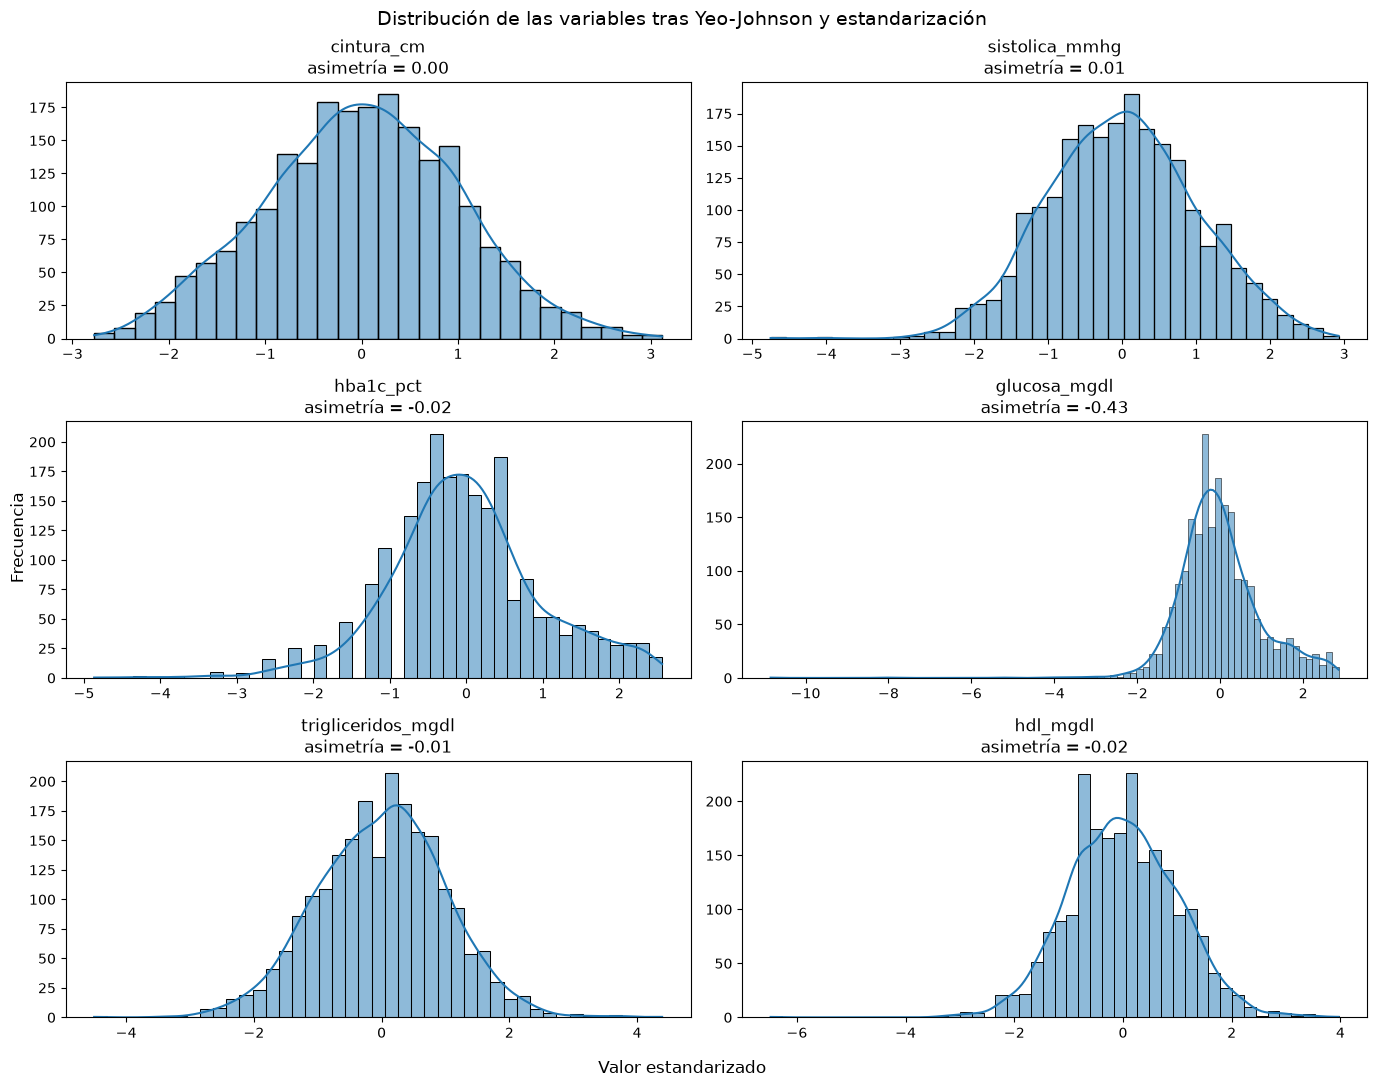

In [15]:
fig, axs = plt.subplots(3, 2, figsize=(14, 11))

for ax, columna in zip(axs.ravel(), df_escalado.columns):
    valores = df_escalado[columna]
    sns.histplot(valores, kde=True, ax=ax)
    ax.set(title=f"{columna}\nasimetría = {valores.skew():.2f}", xlabel="", ylabel="")


fig.suptitle("Distribución de las variables tras Yeo-Johnson y estandarización", fontsize=14)
fig.supxlabel("Valor estandarizado")
fig.supylabel("Frecuencia")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "04_histogramas_transformados.png", dpi=150, bbox_inches="tight")
plt.show()

La transformación de Yeo-Johnson reduce la asimetría de cada variable y la aproxima a una distribución normal (Yeo & Johnson, 2000), lo cual resulta pertinente dado que el modelo de mezclas gaussianas representa cada grupo como una distribución normal multivariada. Además, la estandarización posterior lleva todas las variables a media cero y desviación estándar uno, de modo que ninguna domine el modelo ni las métricas basadas en distancias por estar en una escala mayor, como la cintura en centímetros frente a la HbA1c en porcentaje.

Tras la transformación, casi todas las variables presentan una asimetría cercana a cero, y los histogramas muestran distribuciones más simétricas. La excepción es la glucosa, que conserva una asimetría de −0,43, ya que la transformación intenta volver simétrica una variable que reúne dos poblaciones: participantes con y sin diabetes. Lejos de ser un problema, esta mezcla de poblaciones es precisamente la estructura que un modelo de mezclas está diseñado para capturar, lo que respalda la elección del GMM.

### 6.3 Base depurada

In [16]:
# La base se guarda en escala original para interpretar los perfiles en sus unidades clínicas
base_depurada = df_modelo.join(df_perfil)
base_depurada.to_parquet(ARCHIVO_DEPURADO)
print(f"Base depurada guardada: {base_depurada.shape[0]:,} filas x {base_depurada.shape[1]} columnas")

Base depurada guardada: 2,173 filas x 9 columnas


La base depurada se guarda en escala original y no transformada, puesto que los perfiles de los grupos se interpretan en sus unidades clínicas (cm, mmHg, %, mg/dL), mientras que la versión transformada se reconstruye en cada ejecución a partir de ella.

## 7. Modelo de mezclas gaussianas (GMM)

### 7.1 Justificación de la técnica

Un modelo de mezclas gaussianas supone que los datos provienen de la combinación de varias distribuciones normales multivariadas, cada una con su propia media, matriz de covarianza y proporción, de modo que cada componente representa un grupo (McLachlan & Peel, 2000). A diferencia de los métodos basados únicamente en distancias, el GMM estima para cada participante la probabilidad de pertenecer a cada grupo y permite elegir el número de grupos mediante criterios estadísticos formales como el BIC (Fraley & Raftery, 2002). La elección de esta técnica se sustenta en los cuatro aspectos que se resumen a continuación.

| Aspecto | Características de los datos | Por qué se ajusta el GMM | Evidencia en el notebook |
|---|---|---|---|
| Tipo de variables | Seis variables cuantitativas continuas de razón | El GMM modela densidades de variables continuas | Sección 4 |
| Forma y escala | Variables correlacionadas entre sí y en escalas distintas | Con covarianza completa admite grupos elípticos, inclinados y de distinto tamaño; la estandarización iguala las escalas | Secciones 5.5 y 6.2 |
| Naturaleza del fenómeno | El riesgo cardiometabólico es un continuo sin cortes nítidos entre perfiles | La asignación probabilística refleja que una persona puede estar entre dos perfiles | Sección 6.2 (la glucosa mezcla dos poblaciones) |
| Supuestos | Cada grupo se distribuye como una normal multivariada | La transformación de Yeo-Johnson aproxima las variables a la normalidad | Sección 6.2 |

Por el contrario, se descartan las otras dos técnicas del curso. Por un lado, K-means asume grupos esféricos, de tamaño similar y con asignación rígida, de manera que no puede representar grupos alargados por la correlación entre variables ni personas en transición entre perfiles. Por otro lado, DBSCAN busca regiones densas separadas por zonas de baja densidad (Ester et al., 1996), mientras que los perfiles metabólicos se solapan de forma continua, por lo que tendería a reunir a casi todos los participantes en un único grupo.

### 7.2 Selección del número de grupos y del tipo de covarianza

In [17]:
# Se ajusta un GMM por cada combinación de K y tipo de covarianza
filas = []
for cov in ["full", "tied", "diag", "spherical"]:
    for k in range(1, 9):
        gmm = GaussianMixture(
            n_components=k, covariance_type=cov, n_init=5, random_state=SEMILLA
        ).fit(df_escalado)
        etiquetas = gmm.predict(df_escalado)
        filas.append({
            "covarianza": cov,
            "k": k,
            "BIC": gmm.bic(df_escalado),
            "AIC": gmm.aic(df_escalado),
            # La silueta requiere al menos dos grupos
            "silueta": silhouette_score(df_escalado, etiquetas) if k > 1 else np.nan,
            "n_grupo_menor": np.bincount(etiquetas).min(),
        })

seleccion = pd.DataFrame(filas)

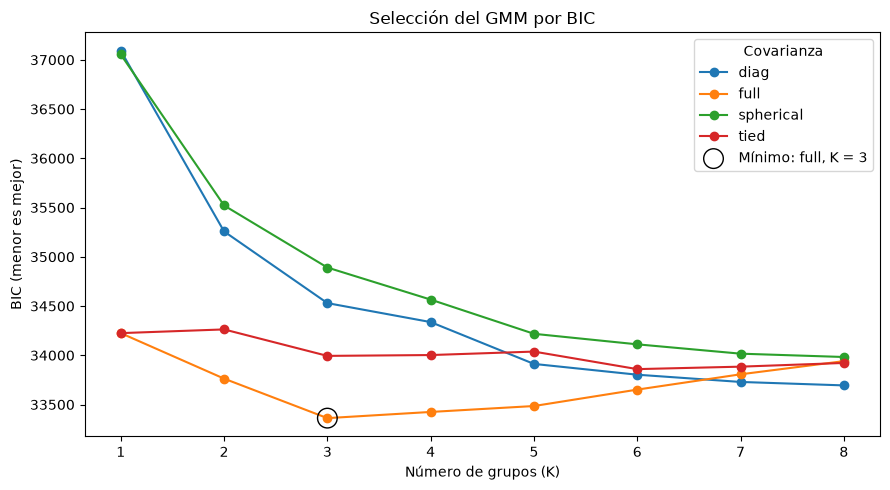

In [18]:
fig, ax = plt.subplots(figsize=(9, 5))
for cov, sub in seleccion.groupby("covarianza"):
    ax.plot(sub["k"], sub["BIC"], marker="o", label=cov)

mejor = seleccion.loc[seleccion["BIC"].idxmin()]
ax.scatter(mejor["k"], mejor["BIC"], s=200, facecolors="none", edgecolors="black", zorder=3,
           label=f"Mínimo: {mejor['covarianza']}, K = {mejor['k']}")

ax.set(xlabel="Número de grupos (K)", ylabel="BIC (menor es mejor)",
       title="Selección del GMM por BIC")
ax.legend(title="Covarianza")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "05_bic.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
# BIC por K (filas) y tipo de covarianza (columnas)
tabla_bic = seleccion.pivot(index="k", columns="covarianza", values="BIC").round(0)
display(tabla_bic)
print(f"Mínimo BIC: covarianza {mejor['covarianza']}, K = {mejor['k']} ({mejor['BIC']:,.0f})")

covarianza,diag,full,spherical,tied
k,,,,
1,37092.0,34225.0,37054.0,34225.0
2,35258.0,33763.0,35521.0,34263.0
3,34530.0,33362.0,34891.0,33994.0
4,34337.0,33425.0,34565.0,34002.0
5,33912.0,33485.0,34218.0,34038.0
6,33803.0,33652.0,34111.0,33860.0
7,33729.0,33807.0,34016.0,33885.0
8,33694.0,33941.0,33983.0,33922.0


Mínimo BIC: covarianza full, K = 3 (33,362)


In [20]:
# Métricas complementarias del modelo con covarianza completa
display(seleccion.query("covarianza == 'full'").set_index("k").drop(columns="covarianza").round(3))

,BIC,AIC,silueta,n_grupo_menor
k,,,,
1,34225.026,34071.561,NaN,2173
2,33763.064,33450.451,0.185,1069
3,33362.020,32890.260,0.151,125
4,33424.723,32793.815,0.131,99
5,33484.883,32694.826,0.144,63
6,33651.536,32702.331,0.123,55
7,33806.897,32698.543,0.108,59
8,33940.628,32673.126,0.091,44


El modelo con menor BIC es el de covarianza completa con tres grupos (K = 3). A diferencia del método del codo, en el BIC no se busca el punto donde la curva deja de descender, sino directamente su mínimo, puesto que el criterio ya equilibra el ajuste del modelo con una penalización por su número de parámetros (Fraley & Raftery, 2002). En este caso, el BIC disminuye de K = 1 a K = 3 y vuelve a aumentar a partir de K = 4, y la diferencia entre K = 3 y K = 4 supera ampliamente los 10 puntos que Kass y Raftery (1995) consideran evidencia muy fuerte a favor del modelo con menor BIC. Además, la covarianza completa supera a las demás estructuras, lo que confirma que los grupos no son esféricos y que la correlación entre variables debe modelarse.

Por su parte, el AIC disminuye casi de forma continua al aumentar K, dado que penaliza la complejidad con menos fuerza que el BIC y tiende a favorecer modelos con más grupos de los necesarios; por ello, no se emplea como criterio de decisión. Asimismo, la silueta es baja para todos los valores de K, lo cual es esperable, ya que esta métrica premia grupos compactos y bien separados (Rousseeuw, 1987), mientras que el GMM está diseñado justamente para grupos que se solapan. En consecuencia, la silueta se reporta como medida de validación, pero la elección del modelo se basa en el BIC.

## 8. Ajuste del modelo final

### 8.1 Ajuste y asignación de los grupos

In [21]:
# El algoritmo EM puede converger a máximos locales; con 30 inicializaciones
# se conserva la solución de mayor verosimilitud
gmm = GaussianMixture(
    n_components=3, covariance_type="full", n_init=30, random_state=SEMILLA
).fit(df_escalado)

log_verosimilitud = gmm.score(df_escalado) * len(df_escalado)
print(f"Convergencia: {gmm.converged_} ({gmm.n_iter_} iteraciones)")
print(f"Log-verosimilitud: {log_verosimilitud:,.1f}")
print(f"BIC: {gmm.bic(df_escalado):,.1f}")

Convergencia: True (25 iteraciones)
Log-verosimilitud: -16,352.9
BIC: 33,343.5


In [22]:
# La numeración de sklearn es arbitraria; los grupos se nombran según su perfil.
# Alto riesgo: componente con mayor HbA1c media; de los dos restantes,
# el más pequeño es el grupo residual y el otro el perfil típico.
componente = gmm.predict(df_escalado)
tamano = np.bincount(componente)

alto_riesgo = int(np.argmax(gmm.means_[:, list(df_modelo.columns).index("hba1c_pct")]))
restantes = [c for c in range(3) if c != alto_riesgo]
residual = min(restantes, key=lambda c: tamano[c])
tipico = max(restantes, key=lambda c: tamano[c])

NOMBRES = {tipico: "Perfil típico", alto_riesgo: "Alto riesgo", residual: "Grupo residual"}
ORDEN = ["Perfil típico", "Alto riesgo", "Grupo residual"]
COLORES = {"Perfil típico": "#4C72B0", "Alto riesgo": "#C44E52", "Grupo residual": "#062E03"}

grupos = pd.Series(componente, index=df_modelo.index).map(NOMBRES).rename("grupo")

resumen_grupos = pd.DataFrame({
    "n": grupos.value_counts(),
    "porcentaje": (grupos.value_counts(normalize=True) * 100).round(1),
    "peso_estimado": pd.Series({NOMBRES[c]: gmm.weights_[c] for c in range(3)}).round(3),
}).loc[ORDEN]
display(resumen_grupos)

,n,porcentaje,peso_estimado
Perfil típico,1547,71.2,0.633
Alto riesgo,552,25.4,0.312
Grupo residual,74,3.4,0.055


El ajuste del modelo se realiza mediante el algoritmo EM, que parte de una configuración inicial aleatoria y mejora la verosimilitud en cada iteración hasta converger. Sin embargo, este algoritmo puede detenerse en un máximo local, de modo que distintas inicializaciones pueden producir soluciones diferentes (McLachlan & Peel, 2000). Por ello, el modelo final se ajusta con 30 inicializaciones y se conserva la de mayor verosimilitud, lo que además reduce ligeramente el BIC respecto al obtenido en la sección 7.

Dado que la numeración que asigna el algoritmo es arbitraria y puede cambiar entre ejecuciones, los grupos se nombran según su perfil. Por un lado, el **perfil típico** reúne a la mayoría de los participantes (71 %) y, por otro, el grupo de **alto riesgo** concentra a una cuarta parte (25 %) y se distingue por presentar la HbA1c media más alta. Finalmente, el **grupo residual** es pequeño (3 %) y, al comparar distintas inicializaciones, es el único cuyo tamaño varía de forma apreciable (entre 73 y 125 participantes), mientras que los otros dos se mantienen. Por lo tanto, este grupo no se interpreta como un perfil clínico, sino como un componente que reúne a los participantes que no se ajustan bien a los otros dos; su estabilidad se evalúa en la sección 9.

### 8.2 Probabilidades de pertenencia

Mediana de la probabilidad máxima: 0.874
Asignación incierta (< 0,8): 789 (36.3%)
Asignación muy incierta (< 0,5): 14 (0.6%)


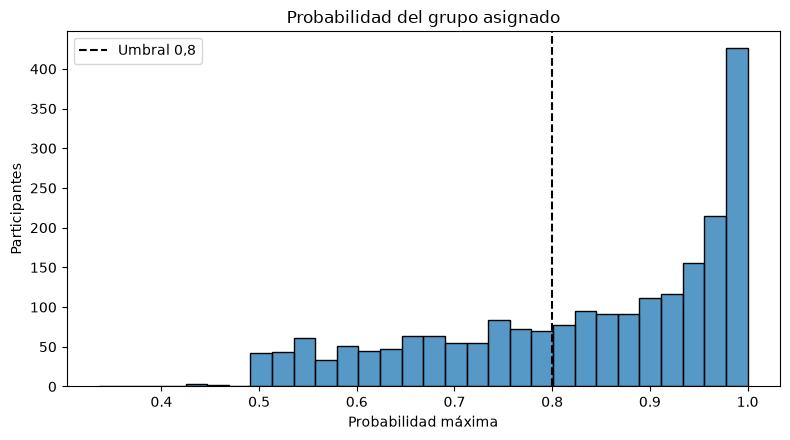

In [23]:
probabilidades = pd.DataFrame(
    gmm.predict_proba(df_escalado), index=df_modelo.index
).rename(columns=NOMBRES)[ORDEN]
prob_max = probabilidades.max(axis=1)

print(f"Mediana de la probabilidad máxima: {prob_max.median():.3f}")
print(f"Asignación incierta (< 0,8): {(prob_max < 0.8).sum():,} ({(prob_max < 0.8).mean():.1%})")
print(f"Asignación muy incierta (< 0,5): {(prob_max < 0.5).sum():,} ({(prob_max < 0.5).mean():.1%})")

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(prob_max, bins=30, ax=ax)
ax.axvline(0.8, color="black", linestyle="--", label="Umbral 0,8")
ax.set(title="Probabilidad del grupo asignado", xlabel="Probabilidad máxima", ylabel="Participantes")
ax.legend()
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "06_probabilidades.png", dpi=150, bbox_inches="tight")
plt.show()

La mediana de la probabilidad máxima es cercana a 0,87, lo que indica que la mayoría de los participantes se asigna a su grupo con alta certeza. No obstante, cerca de un tercio presenta una probabilidad máxima menor de 0,8, aunque muy pocos quedan por debajo de 0,5. Lejos de ser un defecto del modelo, este resultado confirma que el riesgo cardiometabólico se distribuye como un continuo y no en categorías nítidas, de modo que existe un número considerable de personas en transición entre perfiles. Precisamente, esta información no estaría disponible con una técnica de asignación rígida como K-means, y es de interés práctico, puesto que identifica a quienes se encuentran en la frontera hacia el perfil de alto riesgo.

### 8.3 Visualización en componentes principales

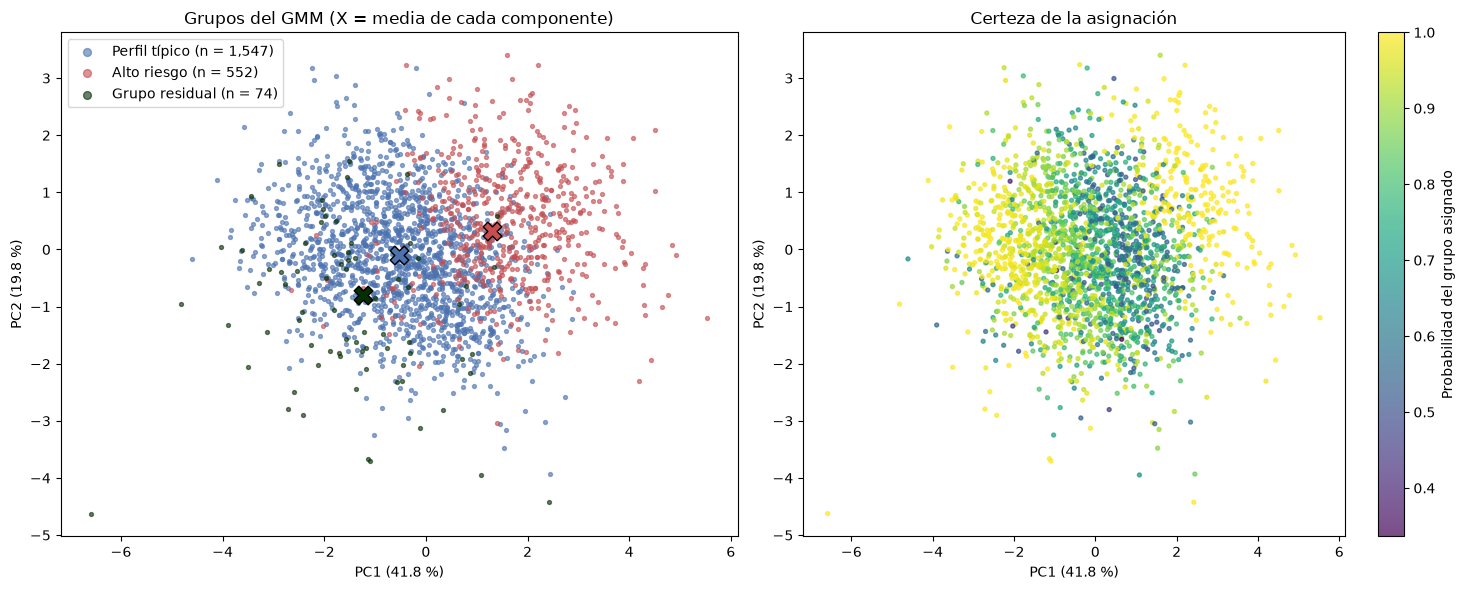

Varianza explicada por el plano: 61.6 %


In [24]:
# El PCA se usa solo para visualizar; el modelo se ajustó en las seis dimensiones
pca = PCA(n_components=2, random_state=SEMILLA)
X_pca = pd.DataFrame(pca.fit_transform(df_escalado), index=df_modelo.index, columns=["PC1", "PC2"])
varianza = pca.explained_variance_ratio_ * 100
centros_pca = pca.transform(gmm.means_)

fig, axs = plt.subplots(1, 2, figsize=(15, 6))

for nombre in ORDEN:
    mascara = grupos == nombre
    axs[0].scatter(X_pca.loc[mascara, "PC1"], X_pca.loc[mascara, "PC2"], s=8, alpha=0.6,
                   color=COLORES[nombre], label=f"{nombre} (n = {mascara.sum():,})")
for c, nombre in NOMBRES.items():
    axs[0].scatter(*centros_pca[c], marker="X", s=180, color=COLORES[nombre], edgecolor="black")
axs[0].set_title("Grupos del GMM (X = media de cada componente)")
axs[0].legend(markerscale=2)

puntos = axs[1].scatter(X_pca["PC1"], X_pca["PC2"], c=prob_max, cmap="viridis", s=8, alpha=0.7)
fig.colorbar(puntos, ax=axs[1], label="Probabilidad del grupo asignado")
axs[1].set_title("Certeza de la asignación")

for ax in axs:
    ax.set(xlabel=f"PC1 ({varianza[0]:.1f} %)", ylabel=f"PC2 ({varianza[1]:.1f} %)")

fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "07_pca_grupos.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Varianza explicada por el plano: {varianza.sum():.1f} %")

In [25]:
cargas = pd.DataFrame(pca.components_.T, index=df_modelo.columns, columns=["PC1", "PC2"])
display(cargas.round(2))

,PC1,PC2
cintura_cm,0.42,-0.13
sistolica_mmhg,0.28,0.43
hba1c_pct,0.46,0.39
glucosa_mgdl,0.47,0.33
trigliceridos_mgdl,0.42,-0.42
hdl_mgdl,-0.38,0.60


Los dos primeros componentes principales explican cerca del 62 % de la varianza, de modo que el gráfico es una proyección aproximada de las seis dimensiones en que se ajustó el modelo y, por ello, exagera el solapamiento entre los grupos. Al revisar las cargas, el primer componente tiene coeficientes positivos en todas las variables excepto la HDL, por lo que puede interpretarse como un eje de carga metabólica general, mientras que el segundo opone la HDL a los triglicéridos (Jolliffe & Cadima, 2016).

En consecuencia, el grupo de alto riesgo se desplaza hacia valores altos del primer componente, lo que concuerda con su mayor carga metabólica, mientras que el perfil típico ocupa la región central. Por su parte, el grupo residual se ubica hacia valores bajos de ambos componentes, pero con una dispersión mayor que la de los otros dos grupos, lo cual es coherente con su interpretación como un componente que reúne participantes heterogéneos. Además, el panel derecho muestra que las asignaciones de menor certeza corresponden en su gran mayoría al perfil típico y al de alto riesgo, y se ubican en la zona donde ambos se encuentran, que es justamente la transición descrita en la sección 8.2.

## 9. Validación

### 9.1 Validación interna

In [26]:
# Índices globales calculados sobre los datos transformados y estandarizados
validacion_interna = pd.Series({
    "Silueta (mayor es mejor, rango -1 a 1)": silhouette_score(df_escalado, grupos),
    "Calinski-Harabasz (mayor es mejor)": calinski_harabasz_score(df_escalado, grupos),
    "Davies-Bouldin (menor es mejor)": davies_bouldin_score(df_escalado, grupos),
}, name="valor").round(3)
display(validacion_interna.to_frame())

,valor
"Silueta (mayor es mejor, rango -1 a 1)",0.164
Calinski-Harabasz (mayor es mejor),257.188
Davies-Bouldin (menor es mejor),2.656


In [27]:
# Silueta individual: valores negativos indican participantes más cercanos a otro grupo
silueta_individual = pd.Series(silhouette_samples(df_escalado, grupos), index=df_modelo.index)

silueta_por_grupo = pd.DataFrame({
    "silueta_media": silueta_individual.groupby(grupos).mean(),
    "porcentaje_negativos": silueta_individual.lt(0).groupby(grupos).mean() * 100,
    "probabilidad_media": prob_max.groupby(grupos).mean(),
}).loc[ORDEN].round(3)
display(silueta_por_grupo)

,silueta_media,porcentaje_negativos,probabilidad_media
grupo,,,
Perfil típico,0.166,12.088,0.832
Alto riesgo,0.192,14.130,0.834
Grupo residual,-0.092,81.081,0.857


Las tres métricas de validación interna coinciden en que los grupos presentan un solapamiento considerable. Por un lado, la silueta global es de 0,164, cercana a cero en una escala de −1 a 1 (Rousseeuw, 1987), y, por otro, el índice de Davies-Bouldin es de 2,66, lo que indica que la dispersión dentro de los grupos supera la distancia entre ellos (Davies & Bouldin, 1979). Por su parte, el índice de Calinski-Harabasz (257,2) no tiene un valor de referencia absoluto, sino que sirve para comparar soluciones sobre los mismos datos (Caliński & Harabasz, 1974).

No obstante, estos resultados no contradicen la elección del modelo, puesto que las tres métricas se basan en distancias y premian grupos compactos y separados, mientras que el GMM está diseñado para distribuciones que se solapan. Por lo tanto, más que un defecto, confirman que los perfiles metabólicos forman un continuo, lo cual es coherente con la proporción de asignaciones inciertas observada en la sección 8.2.

Al revisar la silueta por grupo, el perfil típico y el de alto riesgo presentan valores positivos y solo entre el 12 y el 14 % de sus participantes con silueta negativa. Por el contrario, el grupo residual tiene una silueta media negativa (−0,092) y el 81 % de sus participantes está más cerca de otro grupo que del propio. Dado que la métrica es la misma para los tres grupos, esta diferencia no se explica por sus limitaciones, sino porque el residual es un componente amplio que reúne participantes heterogéneos, lo que confirma que no constituye un perfil con identidad propia.

### 9.2 Estabilidad entre inicializaciones

In [28]:
def jaccard_maximo(mascara_referencia, etiquetas_alternativas):
    """Mayor coincidencia (índice de Jaccard) entre un grupo de referencia y algún grupo alternativo."""
    return max(
        (mascara_referencia & (etiquetas_alternativas == e)).sum()
        / (mascara_referencia | (etiquetas_alternativas == e)).sum()
        for e in np.unique(etiquetas_alternativas)
    )


# El modelo se reajusta con 20 semillas distintas y se compara con la solución final
filas = []
for semilla in range(20):
    alternativa = GaussianMixture(
        n_components=3, covariance_type="full", n_init=10, random_state=semilla
    ).fit(df_escalado).predict(df_escalado)

    fila = {"semilla": semilla, "ARI": adjusted_rand_score(grupos, alternativa)}
    for nombre in ORDEN:
        fila[f"Jaccard {nombre}"] = jaccard_maximo((grupos == nombre).to_numpy(), alternativa)
    filas.append(fila)

estabilidad = pd.DataFrame(filas).set_index("semilla")
display(estabilidad.describe().loc[["mean", "min", "50%", "max"]].round(3))

,ARI,Jaccard Perfil típico,Jaccard Alto riesgo,Jaccard Grupo residual
mean,0.963,0.987,0.966,0.970
min,0.749,0.902,0.807,0.602
50%,0.971,0.990,0.971,0.986
max,0.990,0.997,0.989,1.000


Para evaluar la estabilidad, el modelo se reajustó con 20 semillas distintas y cada solución se comparó con la final mediante el índice de Rand ajustado (ARI), que mide la concordancia entre dos particiones y vale 1 cuando son idénticas y 0 cuando coinciden solo por azar (Hubert & Arabie, 1985), y el índice de Jaccard por grupo, que mide la proporción de participantes compartidos entre un grupo y su equivalente en la otra solución. En este caso, ninguna de las particiones corresponde a etiquetas reales, de modo que ambos índices miden la reproducibilidad del modelo y no su exactitud.

El ARI medio es de 0,963, lo que indica que distintas inicializaciones reproducen prácticamente la misma partición. No obstante, al revisar los valores mínimos se observa que la estabilidad no es homogénea entre grupos: el perfil típico y el de alto riesgo mantienen un Jaccard superior a 0,80 en todas las repeticiones, mientras que el del grupo residual desciende hasta 0,60. Por lo tanto, los dos perfiles principales son robustos, mientras que el grupo residual es el más sensible a la inicialización, lo que concuerda con su silueta negativa y respalda que no se interprete como un perfil clínico.

### 9.3 Validación externa con el diagnóstico de diabetes

In [29]:
# Los códigos 7 (se negó) y 9 (no sabe) quedan como faltantes
DIAGNOSTICO = {1: "Sí", 2: "No", 3: "Limítrofe"}
diagnostico = df_perfil["diabetes_dx"].map(DIAGNOSTICO).rename("diabetes")

conteos = pd.crosstab(grupos, diagnostico).loc[ORDEN, ["No", "Limítrofe", "Sí"]]
porcentajes = (pd.crosstab(grupos, diagnostico, normalize="index") * 100).loc[ORDEN, ["No", "Limítrofe", "Sí"]]

print("Participantes por grupo y diagnóstico")
display(conteos)
print("Porcentaje dentro de cada grupo")
display(porcentajes.round(1))

Participantes por grupo y diagnóstico


diabetes,No,Limítrofe,Sí
grupo,,,
Perfil típico,1437,38,70
Alto riesgo,227,35,290
Grupo residual,68,0,6


Porcentaje dentro de cada grupo


diabetes,No,Limítrofe,Sí
grupo,,,
Perfil típico,93.0,2.5,4.5
Alto riesgo,41.1,6.3,52.5
Grupo residual,91.9,0.0,8.1


In [30]:
# ARI entre los grupos y el diagnóstico (solo respuestas Sí / No)
respuesta_clara = diagnostico.isin(["Sí", "No"])
ari_externo = adjusted_rand_score(diagnostico[respuesta_clara], grupos[respuesta_clara])

# Asociación entre grupo y diagnóstico: prueba chi-cuadrado y V de Cramér
chi2, p_valor, gl, _ = chi2_contingency(conteos)
v_cramer = np.sqrt(chi2 / (conteos.to_numpy().sum() * (min(conteos.shape) - 1)))

print(f"ARI grupos vs. diagnóstico (Sí/No): {ari_externo:.3f}")
print(f"Chi-cuadrado = {chi2:.1f}, gl = {gl}, p = {p_valor:.2e}")
print(f"V de Cramér = {v_cramer:.3f}")

ARI grupos vs. diagnóstico (Sí/No): 0.388
Chi-cuadrado = 718.9, gl = 4, p = 2.86e-154
V de Cramér = 0.407


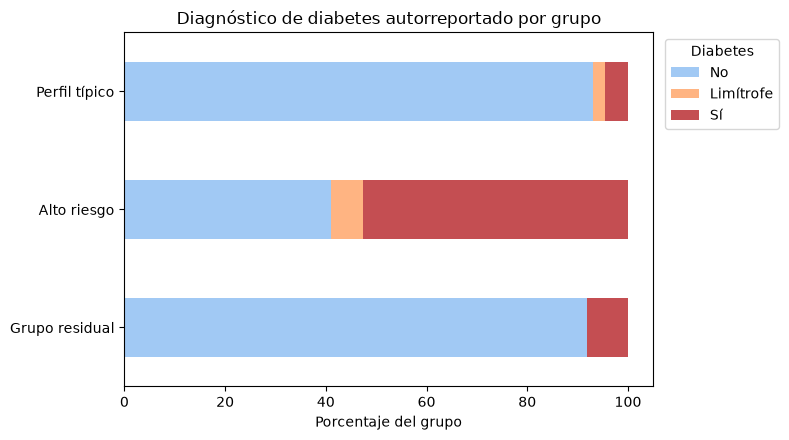

In [31]:
fig, ax = plt.subplots(figsize=(8, 4.5))
porcentajes.plot(kind="barh", stacked=True, ax=ax, color=["#A1C9F4", "#FFB482", "#C44E52"])
ax.set(title="Diagnóstico de diabetes autorreportado por grupo", xlabel="Porcentaje del grupo", ylabel="")
ax.invert_yaxis()
ax.legend(title="Diabetes", bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "08_validacion_externa.png", dpi=150, bbox_inches="tight")
plt.show()

In [32]:
# Discrepancias entre los grupos y el diagnóstico autorreportado
rango_diabetes = df_modelo["hba1c_pct"].ge(6.5) | df_modelo["glucosa_mgdl"].ge(126)
es_alto_riesgo = grupos.eq("Alto riesgo")
con_diagnostico = diagnostico.eq("Sí")

alto_sin_dx = es_alto_riesgo & diagnostico.eq("No")
dx_fuera_alto = con_diagnostico & ~es_alto_riesgo

print(f"Participantes con diagnóstico: {con_diagnostico.sum()}; en alto riesgo: "
      f"{(con_diagnostico & es_alto_riesgo).sum()} ({(con_diagnostico & es_alto_riesgo).sum() / con_diagnostico.sum():.1%})")
print(f"Alto riesgo sin diagnóstico: {alto_sin_dx.sum()}; con valores en rango de diabetes: "
      f"{rango_diabetes[alto_sin_dx].sum()} ({rango_diabetes[alto_sin_dx].mean():.1%})")
print(f"Con diagnóstico fuera de alto riesgo: {dx_fuera_alto.sum()}")
display(df_modelo.loc[dx_fuera_alto, ["hba1c_pct", "glucosa_mgdl"]].median().rename("mediana").to_frame())

Participantes con diagnóstico: 366; en alto riesgo: 290 (79.2%)
Alto riesgo sin diagnóstico: 227; con valores en rango de diabetes: 84 (37.0%)
Con diagnóstico fuera de alto riesgo: 76


,mediana
hba1c_pct,5.9
glucosa_mgdl,107.0


La validación externa compara los grupos con el diagnóstico médico de diabetes autorreportado, una variable que el modelo nunca utilizó. El grupo de alto riesgo concentra la mayor proporción de diagnósticos: el 52,5 % de sus integrantes reporta diabetes, frente al 4,5 % del perfil típico. Visto de otra forma, de los 366 participantes con diagnóstico, 290 (79 %) quedaron en el grupo de alto riesgo, aunque este reúne solo al 25 % de la muestra. Además, la prueba chi-cuadrado confirma que el grupo y el diagnóstico no son independientes (p < 0,001), y la V de Cramér (0,407) indica una asociación fuerte (Cohen, 1988).

No obstante, el ARI es moderado (0,388), lo cual es esperable, puesto que los grupos describen perfiles metabólicos y no reproducen un diagnóstico. En particular, existen dos discrepancias con explicación clínica. Por un lado, de los 227 participantes del grupo de alto riesgo que reportan no tener diabetes, 84 (37 %) presentan HbA1c ≥ 6,5 % o glucosa en ayunas ≥ 126 mg/dL, valores compatibles con una diabetes no diagnosticada, aunque una sola medición no basta para confirmarla (ADA, 2025). Por otro lado, los 76 participantes con diagnóstico que quedaron fuera de este grupo presentan una mediana de HbA1c de 5,9 % y de glucosa de 107 mg/dL, lo que sugiere una diabetes controlada con tratamiento. En consecuencia, el modelo agrupa a los participantes según su estado metabólico actual y, además de concentrar los diagnósticos conocidos, señala posibles casos no detectados por la encuesta.

## 10. Perfilamiento de los grupos

### 10.1 Perfil clínico en escala original

In [33]:
perfil = (
    df_modelo.join(df_perfil[["edad"]])
    .groupby(grupos).median()
    .loc[ORDEN]
)
perfil.insert(0, "n", grupos.value_counts().loc[ORDEN])
perfil["mujeres_%"] = (df_perfil["sexo"].eq(2).groupby(grupos).mean() * 100).loc[ORDEN]

print("Medianas por grupo (edad en años; porcentaje de mujeres)")
display(perfil.round(1))

Medianas por grupo (edad en años; porcentaje de mujeres)


,n,cintura_cm,sistolica_mmhg,hba1c_pct,glucosa_mgdl,trigliceridos_mgdl,hdl_mgdl,edad,mujeres_%
grupo,,,,,,,,,
Perfil típico,1547,96.0,120.7,5.5,101.0,84.0,53.0,48.0,52.8
Alto riesgo,552,109.4,128.8,6.6,132.0,116.0,46.0,61.0,48.0
Grupo residual,74,93.7,121.3,4.9,90.5,84.5,51.0,44.5,37.8


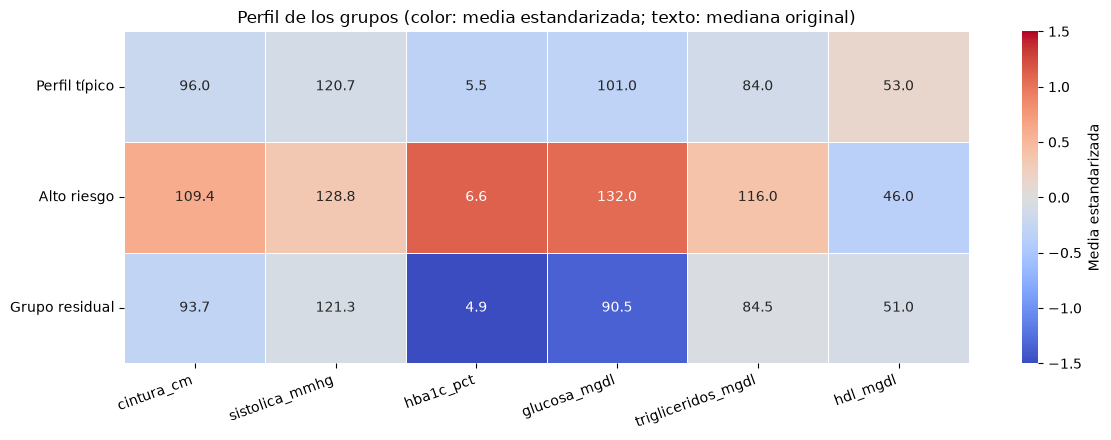

In [34]:
# Color: media estandarizada de cada variable (escala del modelo); texto: mediana original
medias_z = df_escalado.groupby(grupos).mean().loc[ORDEN]
medianas = df_modelo.groupby(grupos).median().loc[ORDEN]

fig, ax = plt.subplots(figsize=(12, 4.5))
sns.heatmap(
    medias_z, cmap="coolwarm", center=0, vmin=-1.5, vmax=1.5,
    annot=medianas.round(1), fmt="", linewidths=0.5,
    cbar_kws={"label": "Media estandarizada"}, ax=ax,
)
ax.set(title="Perfil de los grupos (color: media estandarizada; texto: mediana original)", xlabel="", ylabel="")
ax.tick_params(axis="y", labelrotation=0)
ax.tick_params(axis="x", labelrotation=20)
plt.setp(ax.get_xticklabels(), ha="right")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "09_perfiles.png", dpi=150, bbox_inches="tight")
plt.show()

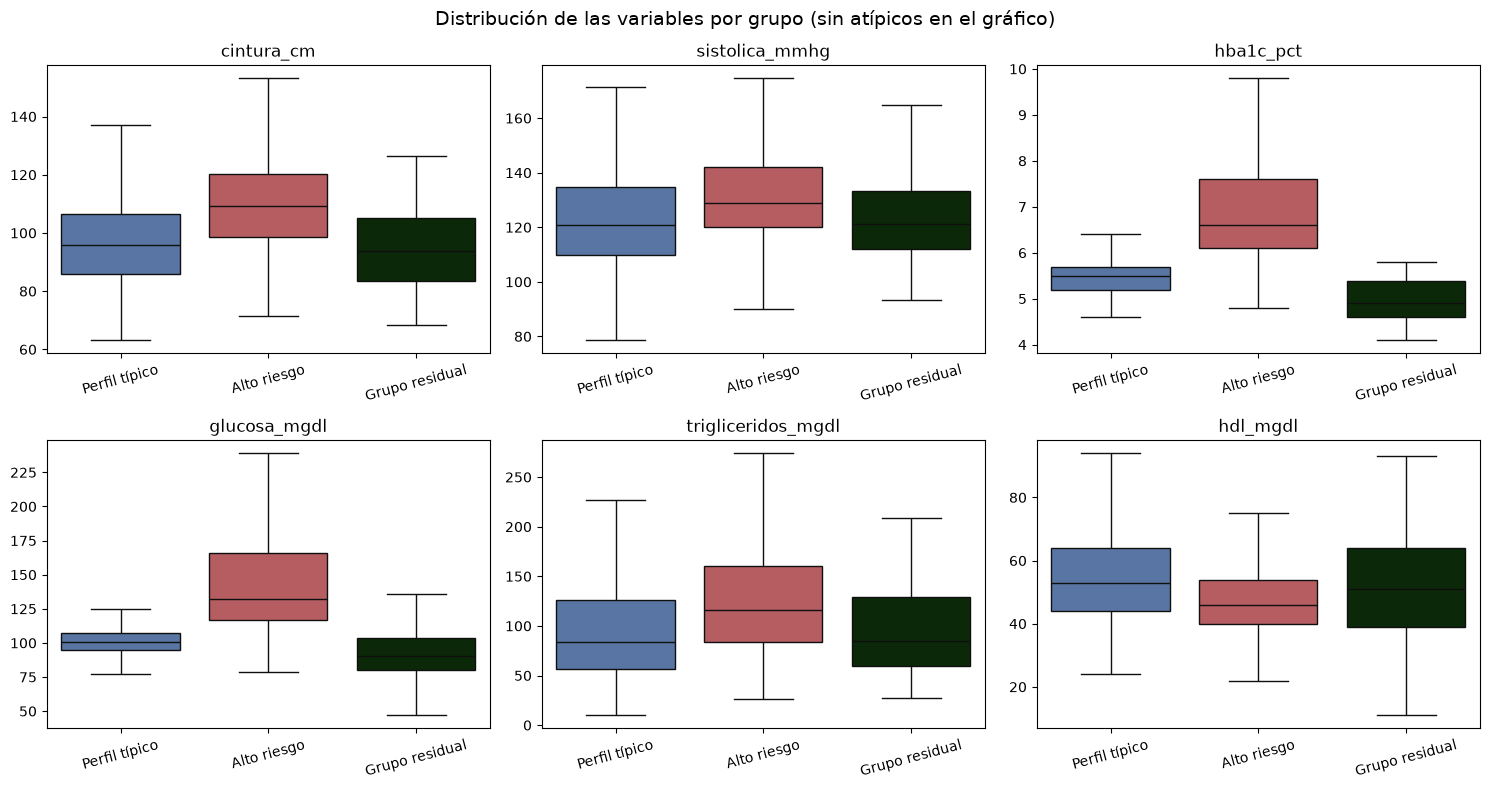

In [35]:
fig, axs = plt.subplots(2, 3, figsize=(15, 8))
for ax, columna in zip(axs.ravel(), df_modelo.columns):
    sns.boxplot(
        x=grupos, y=df_modelo[columna], order=ORDEN, hue=grupos, hue_order=ORDEN,
        palette=COLORES, legend=False, showfliers=False, ax=ax,
    )
    ax.set(title=columna, xlabel="", ylabel="")
    ax.tick_params(axis="x", labelrotation=15)
fig.suptitle("Distribución de las variables por grupo (sin atípicos en el gráfico)", fontsize=14)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "10_boxplots_grupos.png", dpi=150, bbox_inches="tight")
plt.show()

### 10.2 Componentes del síndrome metabólico por grupo

In [36]:
# Umbrales de Alberti et al. (2009); la cintura usa los puntos de corte para población
# estadounidense. Solo se dispone de la presión sistólica y no de los tratamientos,
# por lo que la prevalencia resultante es una aproximación.
es_hombre = df_perfil["sexo"].eq(1)

criterios = pd.DataFrame({
    "Cintura elevada": df_modelo["cintura_cm"].ge(np.where(es_hombre, 102, 88)),
    "Triglicéridos ≥ 150": df_modelo["trigliceridos_mgdl"].ge(150),
    "HDL bajo": df_modelo["hdl_mgdl"].lt(np.where(es_hombre, 40, 50)),
    "Sistólica ≥ 130": df_modelo["sistolica_mmhg"].ge(130),
    "Glucosa ≥ 100": df_modelo["glucosa_mgdl"].ge(100),
}, index=df_modelo.index)
criterios["Síndrome metabólico (≥ 3)"] = criterios.sum(axis=1).ge(3)

prevalencia_criterios = (criterios.groupby(grupos).mean() * 100).loc[ORDEN].round(1)
print("Porcentaje de participantes que cumple cada criterio")
display(prevalencia_criterios)

Porcentaje de participantes que cumple cada criterio


,Cintura elevada,Triglicéridos ≥ 150,HDL bajo,Sistólica ≥ 130,Glucosa ≥ 100,Síndrome metabólico (≥ 3)
grupo,,,,,,
Perfil típico,52.2,16.8,24.0,32.7,57.5,30.1
Alto riesgo,80.4,29.7,41.1,48.0,93.3,64.3
Grupo residual,45.9,20.3,29.7,31.1,29.7,20.3


In [37]:
# Clasificación glucémica según los umbrales de la ADA (2025); categorías excluyentes
rango_prediabetes = (
    df_modelo["glucosa_mgdl"].between(100, 125.99) | df_modelo["hba1c_pct"].between(5.7, 6.49)
)
estado_glucemico = pd.Series(
    np.select([rango_diabetes, rango_prediabetes], ["Rango de diabetes", "Rango de prediabetes"], "Normal"),
    index=df_modelo.index, name="estado_glucemico",
)
distribucion_glucemica = (
    pd.crosstab(grupos, estado_glucemico, normalize="index") * 100
).loc[ORDEN, ["Normal", "Rango de prediabetes", "Rango de diabetes"]]
print("Porcentaje de cada grupo según su estado glucémico")
display(distribucion_glucemica.round(1))

Porcentaje de cada grupo según su estado glucémico


estado_glucemico,Normal,Rango de prediabetes,Rango de diabetes
grupo,,,
Perfil típico,34.5,61.9,3.6
Alto riesgo,6.3,26.4,67.2
Grupo residual,56.8,33.8,9.5


### 10.3 Interpretación de los perfiles

El perfilamiento permite describir cada grupo en términos clínicos. El grupo de **alto riesgo** (25 %) se ubica por encima del promedio en todas las variables de riesgo y por debajo en la HDL, aunque lo que más lo distingue es el componente glucémico, con una HbA1c y una glucosa más de una desviación estándar por encima de la media; en consecuencia, presenta medianas de HbA1c de 6,6 % y de glucosa de 132 mg/dL, ambas en rango de diabetes (ADA, 2025), junto con una mayor cintura (109,4 cm) y una mayor edad (61 años). Además, el 64,3 % de sus integrantes cumple al menos tres criterios de síndrome metabólico (Alberti et al., 2009), casi todos (93,3 %) presentan glucosa en ayunas elevada y dos de cada tres (67,2 %) tienen valores en rango de diabetes.

Por su parte, el **perfil típico** (71 %) se ubica ligeramente por debajo del promedio en todas las variables; sin embargo, no corresponde a una población sana, ya que el 30,1 % cumple criterios de síndrome metabólico, principalmente por la cintura elevada (52,2 %) y la glucosa en ayunas ≥ 100 mg/dL (57,5 %). De hecho, el 61,9 % de este grupo presenta valores de glucosa o HbA1c en rango de prediabetes, mientras que solo el 3,6 % alcanza el rango de diabetes (ADA, 2025). Por lo tanto, este grupo representa una población en la que el riesgo aún es prevenible.

Finalmente, el **grupo residual** (3 %) se distingue casi exclusivamente por una glucemia muy por debajo del promedio, sin un patrón definido en las demás variables, lo que concuerda con su interpretación como un componente heterogéneo y no como un perfil clínico.

## 11. Conclusiones

En respuesta a la pregunta guía, el clustering mediante un modelo de mezclas gaussianas permitió identificar perfiles de riesgo cardiometabólico en adultos estadounidenses a partir de seis mediciones clínicas y de laboratorio. El BIC seleccionó un modelo de tres componentes con covarianza completa, de los cuales dos constituyen perfiles robustos y clínicamente interpretables: un **perfil típico** (71 %), con valores cercanos a la normalidad pero con una alta frecuencia de obesidad abdominal y glucemia alterada en ayunas, y un perfil de **alto riesgo** (25 %), definido sobre todo por valores glucémicos en rango de diabetes, acompañados de mayor cintura, presión arterial y triglicéridos, y menor HDL. El tercer componente (3 %) es inestable y heterogéneo, por lo que no se interpreta como un perfil.

En cuanto a la validez de los resultados, las métricas internas muestran grupos solapados, lo cual es coherente con la naturaleza continua del riesgo cardiometabólico y con la elección de una técnica que asigna probabilidades en lugar de etiquetas rígidas. Aun así, los dos perfiles principales se reproducen de forma consistente entre inicializaciones y, sobre todo, se corresponden con un criterio que el modelo nunca utilizó: el grupo de alto riesgo concentra el 79 % de los diagnósticos de diabetes y, además, señala participantes sin diagnóstico con valores compatibles con la enfermedad.

En consecuencia, los resultados ayudan a resolver la problemática planteada de dos formas. Por un lado, el perfil de alto riesgo identifica a la población que requiere confirmación diagnóstica y seguimiento, incluidos posibles casos no detectados. Por otro, las probabilidades de pertenencia identifican a las personas del perfil típico que se encuentran en la frontera con el perfil de alto riesgo, que constituyen la población objetivo para estrategias de prevención.

Finalmente, los resultados deben interpretarse considerando varias limitaciones. En primer lugar, no se emplearon los pesos muestrales de NHANES, de modo que los grupos describen la muestra analizada y no la población de Estados Unidos (NCHS, s.f.-a). En segundo lugar, el diagnóstico de diabetes es autorreportado y la clasificación glucémica se basa en una sola medición, sin la confirmación que exige el diagnóstico clínico (ADA, 2025). En tercer lugar, los criterios de síndrome metabólico son una aproximación, ya que no se incluyeron la presión diastólica ni los tratamientos farmacológicos (Alberti et al., 2009). Por último, el análisis se restringe a la submuestra en ayunas, lo que reduce el tamaño de la muestra, aunque la sección 5.2 mostró que no introduce sesgo de selección.

## Referencias

Alberti, K. G. M. M., Eckel, R. H., Grundy, S. M., Zimmet, P. Z., Cleeman, J. I., Donato, K. A., Fruchart, J.-C., James, W. P. T., Loria, C. M., & Smith, S. C., Jr. (2009). Harmonizing the metabolic syndrome. *Circulation, 120*(16), 1640–1645. https://doi.org/10.1161/CIRCULATIONAHA.109.192644

American Diabetes Association Professional Practice Committee. (2025). 2. Diagnosis and classification of diabetes: Standards of Care in Diabetes—2025. *Diabetes Care, 48*(Supl. 1), S27–S49. https://doi.org/10.2337/dc25-S002

Caliński, T., & Harabasz, J. (1974). A dendrite method for cluster analysis. *Communications in Statistics, 3*(1), 1–27. https://doi.org/10.1080/03610927408827101

Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2.ª ed.). Lawrence Erlbaum Associates.

Davies, D. L., & Bouldin, D. W. (1979). A cluster separation measure. *IEEE Transactions on Pattern Analysis and Machine Intelligence, PAMI-1*(2), 224–227. https://doi.org/10.1109/TPAMI.1979.4766909

Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. En *Proceedings of the Second International Conference on Knowledge Discovery and Data Mining* (pp. 226–231). AAAI Press.

Fraley, C., & Raftery, A. E. (2002). Model-based clustering, discriminant analysis, and density estimation. *Journal of the American Statistical Association, 97*(458), 611–631. https://doi.org/10.1198/016214502760047131

Hirode, G., & Wong, R. J. (2020). Trends in the prevalence of metabolic syndrome in the United States, 2011–2016. *JAMA, 323*(24), 2526–2528. https://doi.org/10.1001/jama.2020.4501

Hubert, L., & Arabie, P. (1985). Comparing partitions. *Journal of Classification, 2*(1), 193–218. https://doi.org/10.1007/BF01908075

Jolliffe, I. T., & Cadima, J. (2016). Principal component analysis: A review and recent developments. *Philosophical Transactions of the Royal Society A, 374*(2065), Artículo 20150202. https://doi.org/10.1098/rsta.2015.0202

Kass, R. E., & Raftery, A. E. (1995). Bayes factors. *Journal of the American Statistical Association, 90*(430), 773–795. https://doi.org/10.1080/01621459.1995.10476572

McLachlan, G., & Peel, D. (2000). *Finite mixture models*. Wiley. https://doi.org/10.1002/0471721182

National Center for Health Statistics. (2020a). *NHANES 2017-2018: Demographic variables and sample weights (DEMO_J)* [Documentación de datos]. Centers for Disease Control and Prevention. https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DEMO_J.htm

National Center for Health Statistics. (2020b). *NHANES 2017-2018: Plasma fasting glucose (GLU_J)* [Documentación de datos]. Centers for Disease Control and Prevention. https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/GLU_J.htm

National Center for Health Statistics. (s.f.-a). *National Health and Nutrition Examination Survey*. Centers for Disease Control and Prevention. https://www.cdc.gov/nchs/nhanes/

National Center for Health Statistics. (s.f.-b). *NHANES 2017-2018 laboratory data overview*. Centers for Disease Control and Prevention. https://wwwn.cdc.gov/nchs/nhanes/continuousnhanes/overviewlab.aspx?BeginYear=2017

Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7

Schober, P., Boer, C., & Schwarte, L. A. (2018). Correlation coefficients: Appropriate use and interpretation. *Anesthesia & Analgesia, 126*(5), 1763–1768. https://doi.org/10.1213/ANE.0000000000002864

Wang, Q., Würtz, P., Auro, K., Mäkinen, V.-P., Kangas, A. J., Soininen, P., Tiainen, M., Tynkkynen, T., Jokelainen, J., Santalahti, K., Salmi, M., Blankenberg, S., Zeller, T., Viikari, J., Kähönen, M., Lehtimäki, T., Salomaa, V., Perola, M., Jalkanen, S., . . . Ala-Korpela, M. (2016). Metabolic profiling of pregnancy: Cross-sectional and longitudinal evidence. *BMC Medicine, 14*, Artículo 205. https://doi.org/10.1186/s12916-016-0733-0

Yeo, I.-K., & Johnson, R. A. (2000). A new family of power transformations to improve normality or symmetry. *Biometrika, 87*(4), 954–959. https://doi.org/10.1093/biomet/87.4.954